# TemperatureScaling

A post-hoc calibrator that makes the predicted probabilities of a binary classifier more trustworthy.

In [1]:
from mlxtend.evaluate import TemperatureScaling

## Overview

Some classifiers (for example Gaussian naive Bayes) report probabilities that are **over-confident**: when they say "95% sure", they are right far less often. **Temperature scaling** fixes this with a single learned number, the *temperature* $T$. The predicted probability $p$ is converted to a logit, divided by $T$, and converted back:

$$p_{\text{calibrated}} = \sigma\left(\frac{\text{logit}(p)}{T}\right), \qquad \text{logit}(p) = \log\frac{p}{1-p}$$

- $T > 1$ makes the predictions **less** confident (fixes over-confidence).
- $T < 1$ makes them **more** confident (fixes under-confidence).
- $T = 1$ changes nothing.

$T$ is found by minimizing the log loss on a held-out *calibration set*. Because dividing by a positive $T$ never changes the ordering of the predictions and keeps $p = 0.5$ at $0.5$, the **predicted class labels and the accuracy do not change**; only the confidence does.

`TemperatureScaling` works on the predicted probabilities of the positive class (`fit(y_prob, y_target)`), so it can be used with any classifier. It is the natural companion of `mlxtend.evaluate.expected_calibration_error` (to measure) and `mlxtend.plotting.plot_reliability_diagram` (to see).

### References

- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*.

## Example 1 - Fixing an over-confident Naive Bayes classifier

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=8000, n_features=20, n_informative=5, n_redundant=10, random_state=123
)
# 3-way split: the calibrator must be fit on data the classifier has not seen
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.5, random_state=123)
X_cal, X_test, y_cal, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=123)

In [3]:
from sklearn.naive_bayes import GaussianNB
from mlxtend.evaluate import TemperatureScaling, expected_calibration_error

nb = GaussianNB().fit(X_train, y_train)
p_cal = nb.predict_proba(X_cal)[:, 1]
p_test = nb.predict_proba(X_test)[:, 1]

scaler = TemperatureScaling().fit(p_cal, y_cal)
p_test_scaled = scaler.transform(p_test)

print(f"Temperature: {scaler.temperature_:.2f}  (> 1 means the model was over-confident)")
print(f"ECE before: {expected_calibration_error(y_test, p_test):.3f}")
print(f"ECE after:  {expected_calibration_error(y_test, p_test_scaled):.3f}")

Temperature: 3.82  (> 1 means the model was over-confident)
ECE before: 0.072
ECE after:  0.012


The expected calibration error drops sharply on data that was used neither for training nor for calibration.

## Example 2 - Accuracy stays exactly the same

In [4]:
import numpy as np

same_labels = np.array_equal(p_test >= 0.5, p_test_scaled >= 0.5)
print("Predicted labels unchanged:", same_labels)

Predicted labels unchanged: True


## Example 3 - Seeing the difference

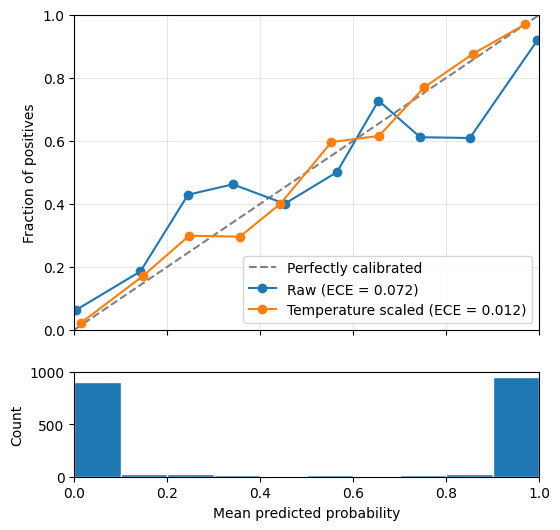

In [5]:
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_reliability_diagram

fig, ax = plot_reliability_diagram(y_test, p_test, label="Raw", figsize=(6, 6))
plot_reliability_diagram(y_test, p_test_scaled, label="Temperature scaled", ax=ax)
plt.show()

The scaled curve (orange) follows the diagonal of perfect calibration more closely than the raw one (blue).

## API

See the class docstring (`help(TemperatureScaling)`) for the full parameter list.